In [1]:
from google.colab import files

uploaded = files.upload()


Saving train.tsv to train.tsv


In [2]:
import pandas as pd

cols = [
    "id","label","statement","subject","speaker","speaker_job",
    "state","party","barely_true_counts","false_counts",
    "half_true_counts","mostly_true_counts",
    "pants_fire_counts","context"
]

df = pd.read_csv(
    "train.tsv",
    sep="\t",
    header=None,
    names=cols
)

df.head()


,id,label,statement,subject,speaker,speaker_job,state,party,barely_true_counts,false_counts,half_true_counts,mostly_true_counts,pants_fire_counts,context
0,2635.json,false,Says the Annies List political group supports ...,abortion,dwayne-bohac,State representative,Texas,republican,0.0,1.0,0.0,0.0,0.0,a mailer
1,10540.json,half-true,When did the decline of coal start? It started...,"energy,history,job-accomplishments",scott-surovell,State delegate,Virginia,democrat,0.0,0.0,1.0,1.0,0.0,a floor speech.
2,324.json,mostly-true,"Hillary Clinton agrees with John McCain ""by vo...",foreign-policy,barack-obama,President,Illinois,democrat,70.0,71.0,160.0,163.0,9.0,Denver
3,1123.json,false,Health care reform legislation is likely to ma...,health-care,blog-posting,NaN,NaN,none,7.0,19.0,3.0,5.0,44.0,a news release
4,9028.json,half-true,The economic turnaround started at the end of ...,"economy,jobs",charlie-crist,NaN,Florida,democrat,15.0,9.0,20.0,19.0,2.0,an interview on CNN


In [7]:
import pandas as pd

# Count the number of missing speakers
missing_count = df['speaker'].isna().sum()
print(f"Number of rows missing a speaker: {missing_count}")

missing_speakers_df = df[df['speaker'].isna()]
display(missing_speakers_df.head())

Number of rows missing a speaker: 2


,id,label,statement,subject,speaker,speaker_job,state,party,barely_true_counts,false_counts,half_true_counts,mostly_true_counts,pants_fire_counts,context
2142,638.json,false,The fact is that although we have had a presid...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9375,1626.json,false,"Joe, I keep hearing you every morning talking ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
# Calculate and display the number of duplicate rows removed
initial_rows = len(df)
duplicate_count = df.duplicated().sum()
df = df.drop_duplicates()
final_rows = len(df)

print(f"Number of duplicate rows removed: {duplicate_count}")
print(f"Dataset size: {initial_rows} -> {final_rows}")

Number of duplicate rows removed: 0
Dataset size: 10240 -> 10240


/tmp/ipykernel_580/3336917026.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_speakers.values, y=top_speakers.index, ax=ax1, palette="viridis")


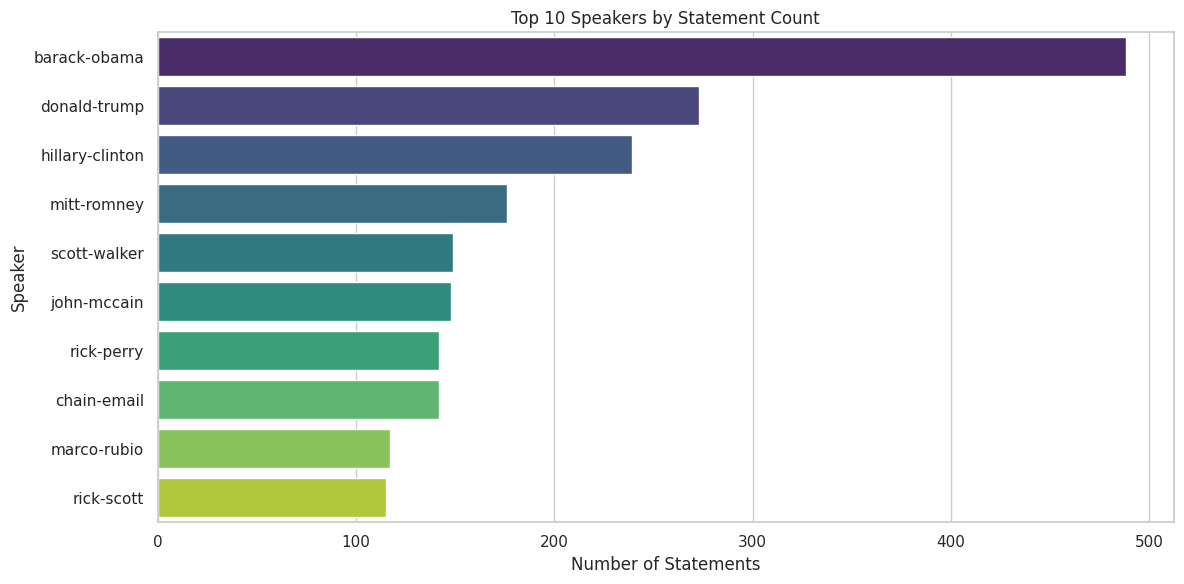

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the aesthetic style for the plots
sns.set_theme(style="whitegrid")

# 1. Plot the Top 10 Speakers
fig1, ax1 = plt.subplots(figsize=(12, 6))
top_speakers = df['speaker'].value_counts().head(10)
sns.barplot(x=top_speakers.values, y=top_speakers.index, ax=ax1, palette="viridis")
ax1.set_title("Top 10 Speakers by Statement Count")
ax1.set_xlabel("Number of Statements")
ax1.set_ylabel("Speaker")
plt.tight_layout()
plt.show()

# Save the top 10 speakers plot
fig1.savefig("top10_speakersplot.png")

/tmp/ipykernel_580/860993903.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_counts.loc[existing_order].values, y=label_counts.loc[existing_order].index, ax=ax2, palette="RdYlGn_r")


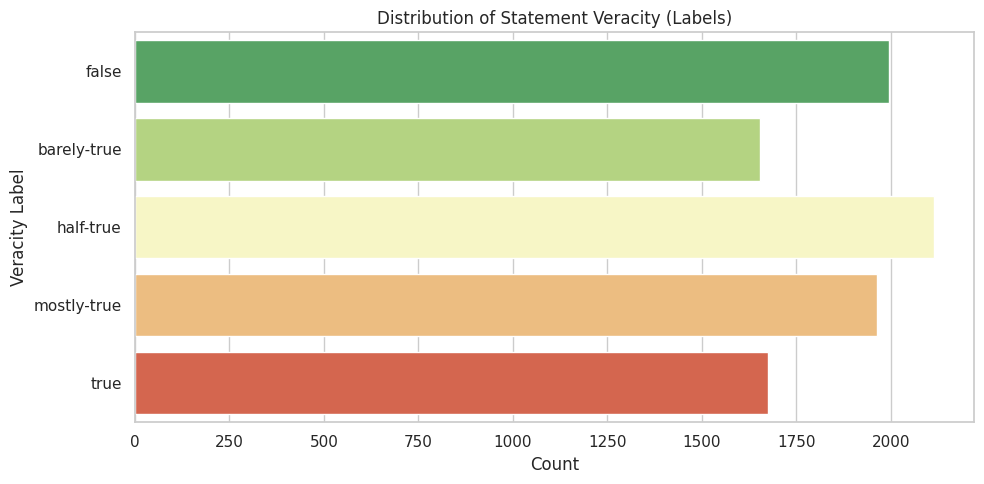

In [11]:
# 2. Plot the Distribution of Labels (Truth-values / "Lie Rates")
fig2, ax2 = plt.subplots(figsize=(10, 5))
label_counts = df['label'].value_counts()

# Reordering for logical flow if standard LIAR dataset labels are used
label_order = ['pants-on-fire', 'false', 'barely-true', 'half-true', 'mostly-true', 'true']
existing_order = [l for l in label_order if l in label_counts.index]

sns.barplot(x=label_counts.loc[existing_order].values, y=label_counts.loc[existing_order].index, ax=ax2, palette="RdYlGn_r")
ax2.set_title("Distribution of Statement Veracity (Labels)")
ax2.set_xlabel("Count")
ax2.set_ylabel("Veracity Label")
plt.tight_layout()
plt.show()

# Save the distribution plot
fig2.savefig("lie_ratesplot.png")

In [4]:
import matplotlib.pyplot as plt
plt.savefig("top10_speakers.png")
plt.savefig("lie_rates.png")

<Figure size 640x480 with 0 Axes>

In [5]:
from google.colab import files

files.download("top10_speakers.png")
files.download("lie_rates.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
files.download("top10_speakersplot.png")
files.download("lie_ratesplot.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
# Print top speakers by overall statement count
print("--- Top 10 Speakers (by total statement count) ---")
print(top_speakers)
print("\n")

# Calculate who has the most 'untrue' statements
# We will filter the dataset for statements labeled 'false', 'barely-true', or 'pants-fire'
lie_labels = ['false', 'barely-true', 'pants-fire']
liars_df = df[df['label'].isin(lie_labels)]

top_liars = liars_df['speaker'].value_counts().head(10)
print("--- Top 10 Speakers by Untrue Statements (False, Barely-True, Pants-on-Fire) ---")
print(top_liars)

--- Top 10 Speakers (by total statement count) ---
speaker
barack-obama       488
donald-trump       273
hillary-clinton    239
mitt-romney        176
scott-walker       149
john-mccain        148
rick-perry         142
chain-email        142
marco-rubio        117
rick-scott         115
Name: count, dtype: int64


--- Top 10 Speakers by Untrue Statements (False, Barely-True, Pants-on-Fire) ---
speaker
donald-trump       201
barack-obama       131
chain-email        125
mitt-romney         72
rick-perry          68
scott-walker        65
hillary-clinton     63
john-mccain         63
ted-cruz            61
blog-posting        51
Name: count, dtype: int64


In [15]:
# Print the dataset shape
print(f"Dataset Shape: {df.shape}")
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}\n")

# Calculate and display the percentage of each veracity label
print("--- Statement Veracity Percentages ---")
label_percentages = df['label'].value_counts(normalize=True) * 100
for label, pct in label_percentages.items():
    print(f"{label:<15}: {pct:.2f}%")

Dataset Shape: (10240, 14)
Total Rows: 10240, Total Columns: 14

--- Statement Veracity Percentages ---
half-true      : 20.64%
false          : 19.48%
mostly-true    : 19.16%
true           : 16.37%
barely-true    : 16.15%
pants-fire     : 8.19%
